# Unsupervised Learning and Anomaly Detection

In the previous chapters every training example came with a label: the strength of the concrete, the failure of the machine, the type of defect. In engineering, labels are often the scarcest resource. Failures are rare, new fault types appear that nobody has seen before, and expert labelling is slow and expensive. Yet we usually have plenty of data from **normal operation**.

Unsupervised learning finds structure in data without labels. In this chapter we use it for three purposes: to compress hundreds of correlated sensor signals into a few meaningful components (PCA), to monitor a process by detecting deviations from its normal behaviour, and to group operating states or products into clusters.

::: {.scenario}
**Scenario: an online alarm for the fab**

After the analysis in Chapter 2, the semiconductor fab decided to try an unsupervised approach: a monitoring system that learns normal runs and raises an alarm for unusual ones, without needing labelled failures. Process engineering accepts an alarm only if it catches at least half of the failed runs while raising false alarms on at most 5 % of the good runs – otherwise operators will ignore it.

**Your decision:** Install the PCA-based alarm in the production line?
:::

**Learning goals.** After this chapter you can

- distinguish supervised and unsupervised learning and name engineering uses of the latter,
- reduce high-dimensional process data with principal component analysis (PCA) and interpret scores, loadings and explained variance,
- monitor a process with PCA-based statistics (Hotelling's T², SPE) and control limits,
- group data with k-means and DBSCAN and choose the number of clusters,
- detect anomalies with Isolation Forest and evaluate detectors when a few labels are available.

**Datasets in this chapter**

- [SECOM (UCI)](https://archive.ics.uci.edu/dataset/179/secom)
- [Condition Monitoring of Hydraulic Systems (UCI)](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)

## Principal component analysis

Process data are highly redundant: dozens of temperatures in the same furnace, pressures along the same line, currents of coupled drives all move together. PCA exploits this redundancy.

::: {.callout-note}
## Definition: Principal component analysis (PCA)
Given standardised data $Z \in \mathbb{R}^{n \times p}$ (each column with mean 0 and standard deviation 1), PCA finds orthogonal directions $v_1, v_2, \dots$ (the **loadings**) such that the projection of the data onto $v_1$ has maximal variance, the projection onto $v_2$ has maximal variance among all directions orthogonal to $v_1$, and so on. The projections $Z v_j$ of the data onto the loadings are the **scores** of component $j$. Computationally, PCA is the singular value decomposition
$$Z = U \Sigma V^\top,$$
where the columns of $V$ are the loadings and the variance explained by component $j$ is proportional to the squared singular value $\sigma_j^2$.
:::

Keeping the first $k$ components gives the best possible approximation of the data by a $k$-dimensional plane (in the least-squares sense). The **scree plot** (explained variance per component) and the cumulative explained variance help to choose $k$.

::: {.callout-warning}
## Pitfall: standardise before PCA
PCA maximises variance, and variance depends on units. Without standardisation, a pressure in Pa (values around $10^5$) dominates a temperature in °C. Standardise unless all variables share a unit and their natural variances are meaningful.
:::

## Process monitoring with PCA

The idea of multivariate statistical process control: build a PCA model from data of **normal operation** (phase I) and then check every new observation against it (phase II). Two complementary statistics measure the deviation:

![Geometry of PCA monitoring, shown for two correlated sensors and a one-component model (in practice: many sensors and a model plane of several components). Hotelling's T² measures how unusual an observation is *within* the model (an extreme value along the known pattern); the squared prediction error SPE measures its distance *from* the model (a new kind of variation the model has never seen).](images/pca-monitoring.png){#fig-pcamon width=75%}

::: {.callout-note}
## Definition: Hotelling's T² and SPE
Let $V_k = [v_1, \dots, v_k]$ contain the first $k$ loadings and $\lambda_j$ be the variance of the scores of component $j$ in the normal-operation data. For a new standardised observation $z$ with scores $t = V_k^\top z = (t_1, \dots, t_k)^\top$:
$$T^2 = \sum_{j=1}^k \frac{t_j^2}{\lambda_j}, \qquad \text{SPE} = \|z - V_k t\|^2 .$$
Control limits are derived from the normal-operation data, e.g. as the 99 % quantile of each statistic.
:::

When an alarm occurs, **contribution plots** show which original variables contribute most to the large T² or SPE value – a first hint for the operator where to look.

## Clustering

Clustering groups observations so that members of a group are similar and different groups are dissimilar. Engineering uses: identifying operating modes of a machine (idle, part load, full load), grouping products or customers, finding families of similar faults.

::: {.callout-note}
## Definition: k-means
k-means partitions the data into $k$ clusters by minimising the within-cluster sum of squared distances to the cluster centres. The algorithm alternates two steps until convergence: (1) assign each point to the nearest centre, (2) move each centre to the mean of its points. The result depends on the starting centres, so the algorithm is run several times.
:::

k-means assumes roughly spherical clusters of similar size, and $k$ must be chosen: the **elbow** of the within-cluster sum of squares or the **silhouette score** (how much closer a point is to its own cluster than to the next one, between −1 and 1) help. **DBSCAN** instead defines clusters as dense regions: it finds clusters of arbitrary shape, determines their number itself and labels points in sparse regions as noise – a natural link to anomaly detection.

## Anomaly detection

::: {.callout-note}
## Definition: Isolation Forest
An Isolation Forest builds random trees that split the data at random features and random thresholds. Anomalies are "few and different": they are isolated after few splits. The **anomaly score** is derived from the average path length needed to isolate a point – short paths mean anomalous.
:::

::: {.callout-tip}
## Engineering practice: evaluating unsupervised detectors
Even if the detector is trained without labels, a few labelled faults are invaluable for **evaluating** it. Use them only for evaluation and threshold selection, never for training – and fit the model on normal data that is separate from the normal data used for evaluation.
:::

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Live coding: PCA monitoring of semiconductor production

We use the SECOM data introduced in Chapter 2: 1,567 production runs, 590 process measurements, and a pass/fail label. Following the preparation from Chapter 2, we remove sparse and constant features, impute the remaining gaps with the median and standardise. All preprocessing steps and the PCA model are fitted on **passed runs only** – this is our model of normal operation.

Label column: 'class', measurement columns: 590, ignored non-numeric columns: ['timestamp']


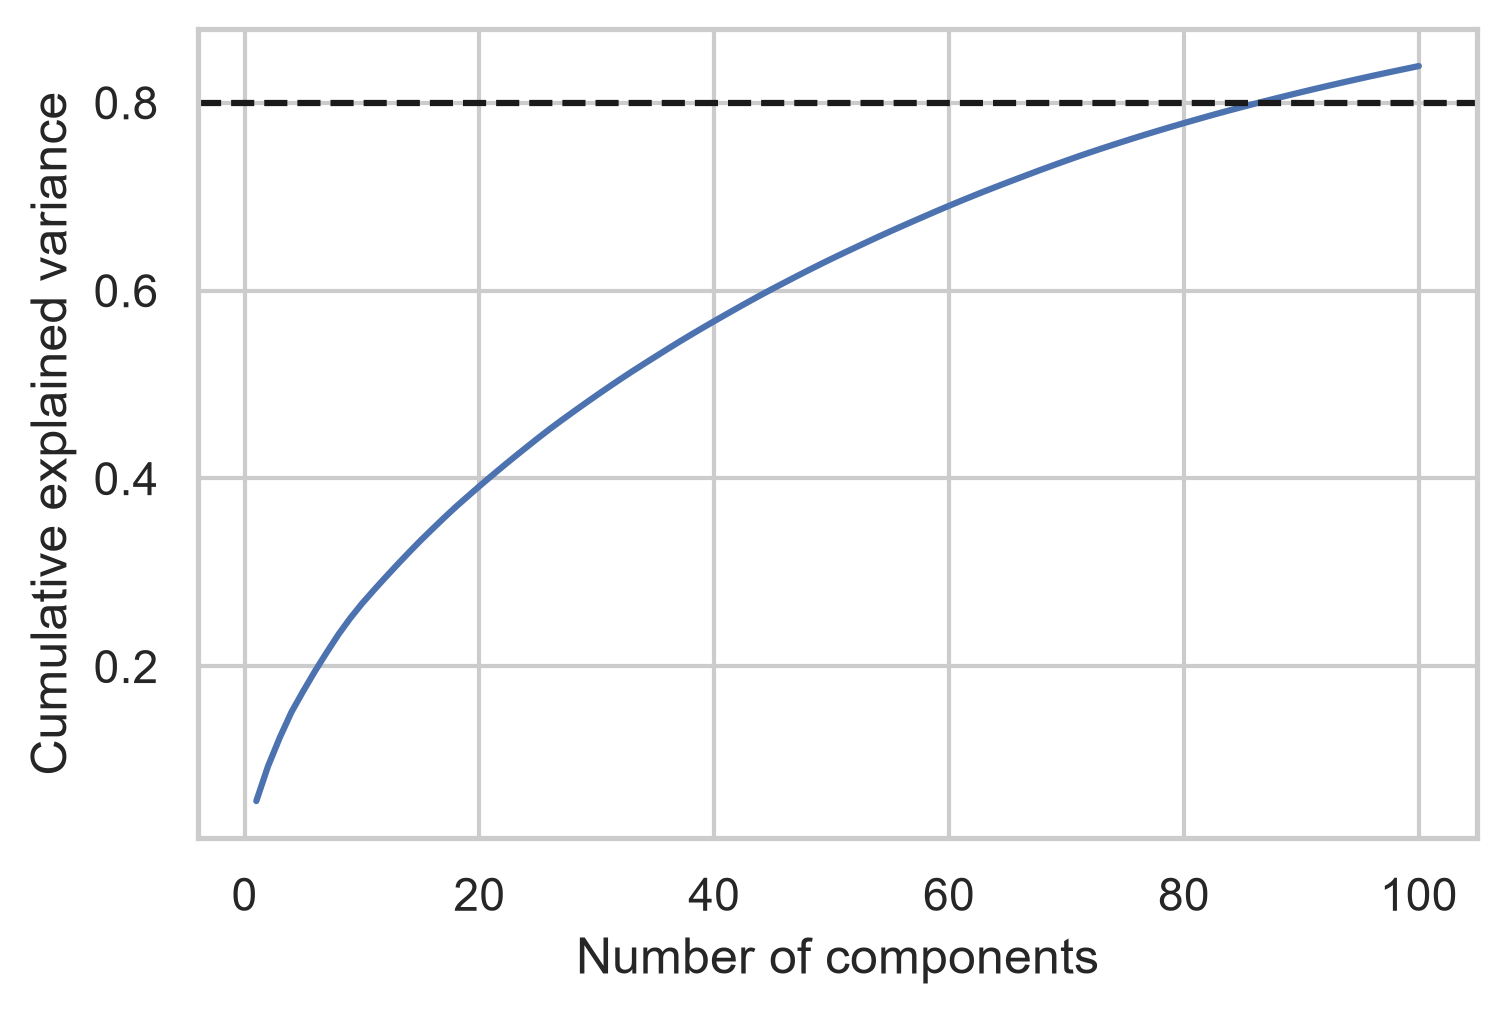

Components for 80 % variance: 87


In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def load_secom():
    """SECOM: return the process measurements X and the label y (-1 = pass, 1 = fail).

    In the UCI repository the label is not marked as target variable, so we find it
    ourselves: the only numeric column whose values are exactly -1 and 1.
    """
    df = fetch_ucirepo(id=179).data.original
    num = df.select_dtypes("number")
    labels = [c for c in num.columns if set(num[c].dropna().unique()) == {-1, 1}]
    if len(labels) != 1:
        labels = [c for c in df.columns if any(k in str(c).lower() for k in ("pass", "fail", "label"))]
    assert len(labels) == 1, f"Label column not found unambiguously: {labels}"
    y = df[labels[0]].astype(int)
    X = num.drop(columns=labels, errors="ignore")
    print(f"Label column: {labels[0]!r}, measurement columns: {X.shape[1]}, "
          f"ignored non-numeric columns: {[c for c in df.columns if c not in num.columns]}")
    return X, y

X, y = load_secom()                          # helper from Chapter 2
X = X.loc[:, X.isna().mean() < 0.5]          # drop features with > 50 % missing

prep = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(1e-8), StandardScaler())
Z = prep.fit_transform(X[y == -1])           # model of normal operation
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
k = int(np.searchsorted(cum, 0.80) + 1)
plt.plot(np.arange(1, 101), cum[:100]); plt.axhline(0.8, ls="--", c="k")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.show()
print("Components for 80 % variance:", k)

**Discussion.** The cumulative explained variance rises steeply for the first components and then slowly. For SECOM, many components are needed to reach 80 % – the process has many partly independent sources of variation, and much of the variance is noise. The choice of 80 % is a convention; in monitoring, the number of components is often chosen by cross-validation of the reconstruction error or by the scree plot's elbow.

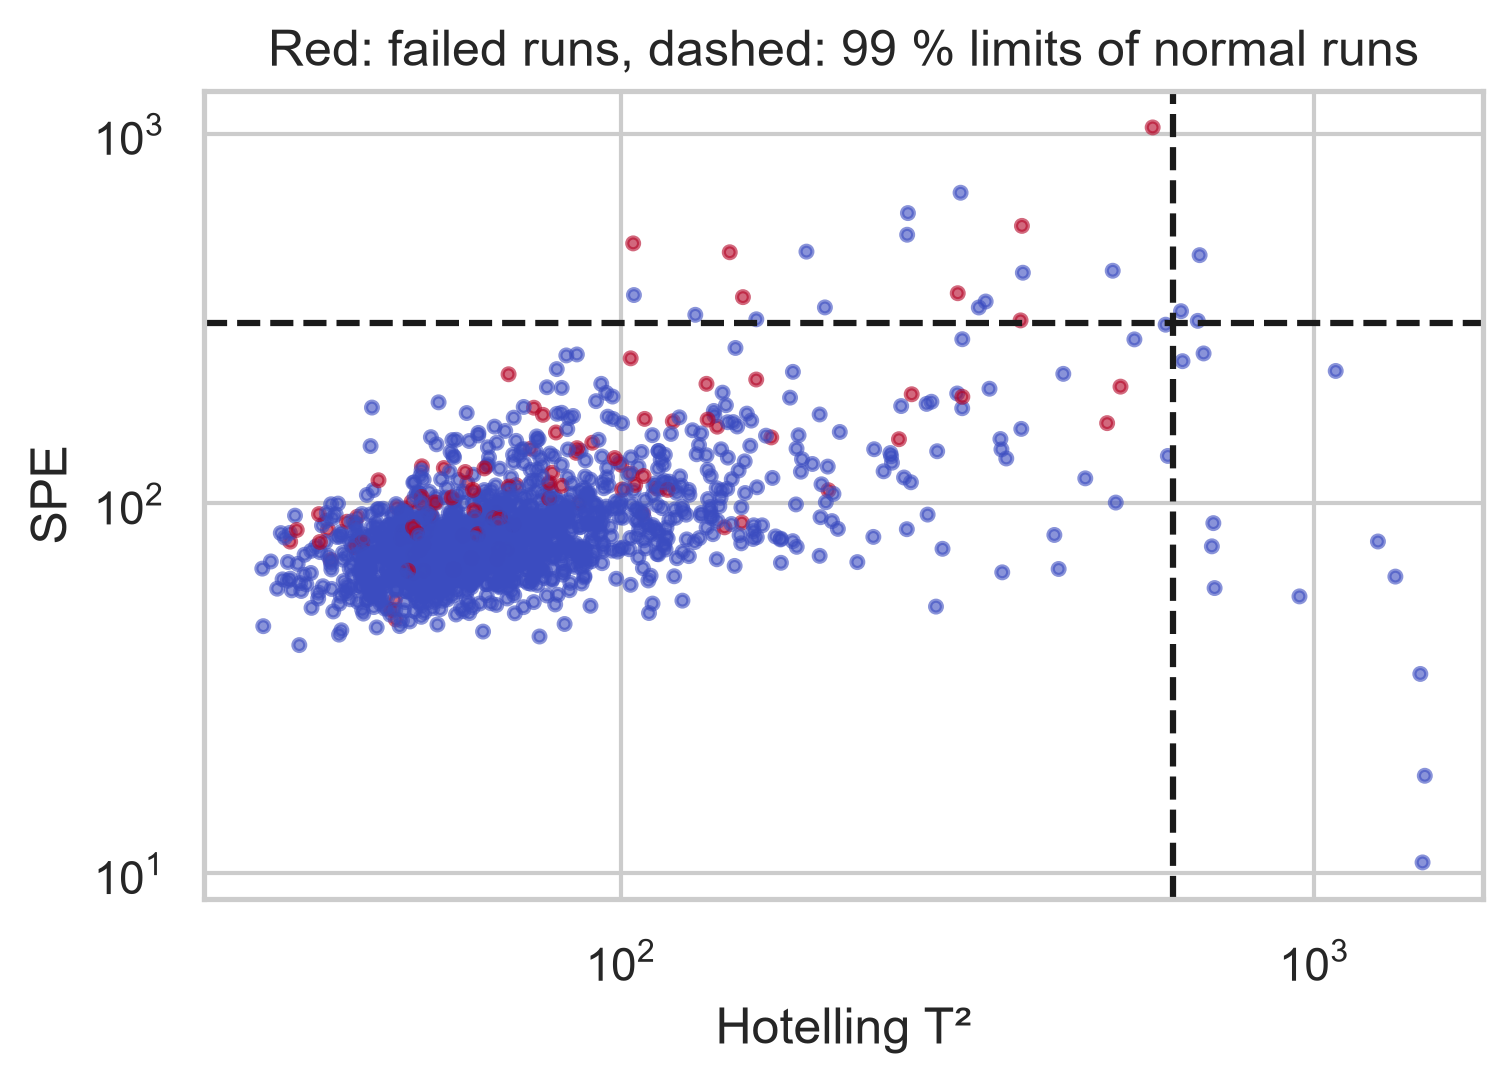

In [3]:
#| code-fold: false
pca_k = PCA(k).fit(Z)

def t2_spe(Zx):
    scores = pca_k.transform(Zx)
    t2 = np.sum(scores**2 / pca_k.explained_variance_, axis=1)
    spe = np.sum((Zx - pca_k.inverse_transform(scores))**2, axis=1)
    return t2, spe

t2, spe = t2_spe(prep.transform(X))
t2_lim, spe_lim = np.percentile(t2[y == -1], 99), np.percentile(spe[y == -1], 99)

plt.scatter(t2, spe, c=(y == 1), cmap="coolwarm", s=8, alpha=0.6)
plt.axvline(t2_lim, c="k", ls="--"); plt.axhline(spe_lim, c="k", ls="--")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("Hotelling T²"); plt.ylabel("SPE")
plt.title("Red: failed runs, dashed: 99 % limits of normal runs")
plt.show()

**Discussion.** The dashed lines are the 99 % limits of the normal runs, so about 1 % of normal runs exceed each limit by construction (false alarms). Failed runs that exceed a limit are detected; those inside the limits look normal to the model. If most failures lie inside the limits, the measured variables may not contain the cause of the failure, or the failure manifests itself in variables that were removed, or in a way that PCA does not capture.

In [4]:
#| code-fold: false
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

iso = IsolationForest(n_estimators=300, random_state=0).fit(Z)
score = -iso.score_samples(prep.transform(X))
print(f"ROC AUC  Isolation Forest: {roc_auc_score(y == 1, score):.3f}")
print(f"ROC AUC  T²:               {roc_auc_score(y == 1, t2):.3f}")
print(f"ROC AUC  SPE:              {roc_auc_score(y == 1, spe):.3f}")

ROC AUC  Isolation Forest: 0.571
ROC AUC  T²:               0.528
ROC AUC  SPE:              0.741


::: {.callout-warning}
## Pitfall: evaluating on the training data
In this quick comparison, the normal runs used to fit the models are also part of the evaluation. They naturally look "very normal" to the models, which makes the result optimistic. Exercise 1 repeats the evaluation properly with separate normal runs.
:::

For SECOM, expect modest AUC values: fault detection in semiconductor manufacturing from summary process data is known to be hard. This is a realistic lesson – many sensors do not guarantee that the relevant information is in the data.

## Back to the decision

The requirement fixes the false alarm rate at 5 %, so we set the alarm limit at the 95 % quantile of the statistic on *good* runs and then measure which share of the failed runs exceeds it. To avoid the optimism discussed above, we fit preprocessing and PCA on 70 % of the good runs and evaluate on the remaining good runs plus all failed runs.

In [5]:
#| code-fold: false
from sklearn.model_selection import train_test_split

X_good_fit, X_good_eval = train_test_split(X[y == -1], test_size=0.3, random_state=0)
prep_d = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(1e-8), StandardScaler())
Z_fit = prep_d.fit_transform(X_good_fit)
pca_d = PCA(k).fit(Z_fit)

def spe_of(Zx):
    return np.sum((Zx - pca_d.inverse_transform(pca_d.transform(Zx)))**2, axis=1)

limit = np.percentile(spe_of(prep_d.transform(X_good_eval)), 95)
detection = (spe_of(prep_d.transform(X[y == 1])) > limit).mean()
print(f"False alarm rate on good runs: 5 % (by construction), detection rate of failed runs: {detection:.0%}")
print("Decision:", "install the alarm." if detection >= 0.5 else "do not install – the alarm would miss too many failures.")

False alarm rate on good runs: 5 % (by construction), detection rate of failed runs: 11%
Decision: do not install – the alarm would miss too many failures.


(Strictly, the limit should be set on one part of the held-out good runs and the false alarm rate checked on another; with a few hundred good runs we accept this simplification.) If the detection rate falls short, the result is still valuable: it tells the fab that the summary data do not contain enough information about the failures – and that investing in different measurements is more promising than tuning the algorithm.

## Live coding: operating states of a hydraulic test rig

The hydraulic dataset was recorded on a test rig in which the condition of four components – cooler, valve, pump and accumulator – was varied deliberately. Each of the 2,205 load cycles lasts 60 seconds; 17 sensors were recorded at up to 100 Hz. The file `profile.txt` contains the component conditions, e.g. the cooler efficiency (3 %, 20 % or 100 %). We compute simple features per cycle from the temperature sensors and the cooling efficiency and see whether PCA and k-means recover the cooler condition **without** using the labels.

In [6]:
#| code-fold: false
import zipfile, io, requests
from pathlib import Path

DATA = Path("data"); DATA.mkdir(exist_ok=True)
hz = DATA / "hydraulic.zip"
if not hz.exists():
    hz.write_bytes(requests.get("https://archive.ics.uci.edu/static/public/447/"
                                "condition+monitoring+of+hydraulic+systems.zip", timeout=300).content)

def read_sensor(z, name):
    member = next(n for n in z.namelist() if n.endswith(name))
    return pd.read_csv(z.open(member), sep="\t", header=None).values

with zipfile.ZipFile(hz) as z:
    sensors = {s: read_sensor(z, f"{s}.txt") for s in ["TS1", "TS2", "TS3", "TS4", "CE", "CP"]}
    profile = pd.DataFrame(read_sensor(z, "profile.txt"),
                           columns=["cooler", "valve", "pump_leak", "accumulator", "stable"])

feat = pd.DataFrame({f"{s}_{stat}": getattr(np, stat)(v, axis=1)
                     for s, v in sensors.items() for stat in ["mean", "std"]})
feat.shape

(2205, 12)

C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


Silhouette scores: {2: 0.543, 3: 0.551, 4: 0.542, 5: 0.558, 6: 0.563}


C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


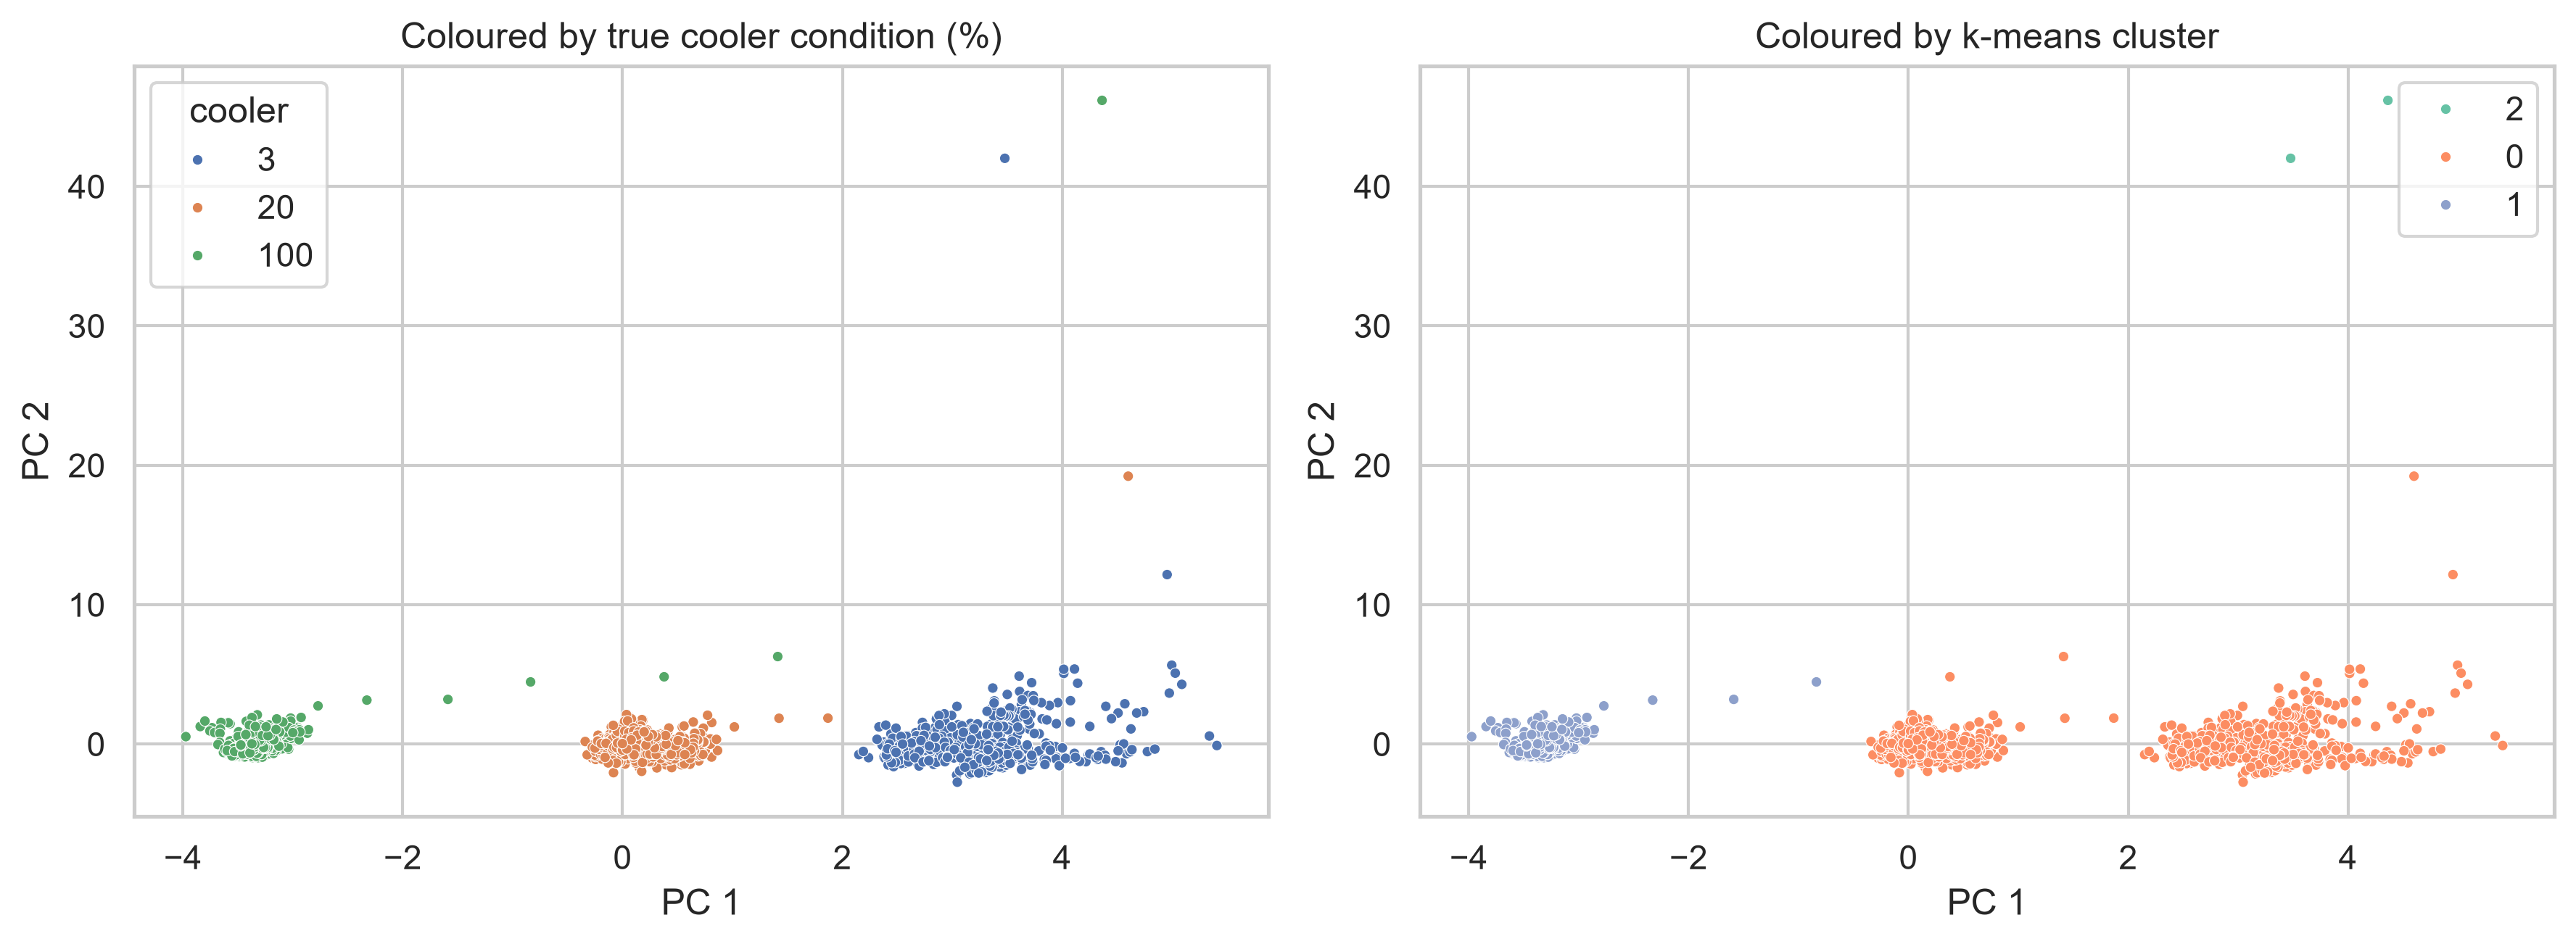

cluster,0,1,2
cooler %,,,
3,731,0,1
20,732,0,0
100,2,738,1


In [7]:
#| code-fold: false
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Zh = StandardScaler().fit_transform(feat)
scores_h = PCA(2).fit_transform(Zh)

sil = {k_: silhouette_score(Zh, KMeans(k_, n_init=10, random_state=0).fit_predict(Zh)) for k_ in range(2, 7)}
print("Silhouette scores:", {k_: round(v, 3) for k_, v in sil.items()})
clusters = KMeans(3, n_init=10, random_state=0).fit_predict(Zh)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=scores_h[:, 0], y=scores_h[:, 1], hue=profile["cooler"].astype(int).astype(str),
                ax=axes[0], s=12).set(title="Coloured by true cooler condition (%)", xlabel="PC 1", ylabel="PC 2")
sns.scatterplot(x=scores_h[:, 0], y=scores_h[:, 1], hue=clusters.astype(str), ax=axes[1], s=12,
                palette="Set2").set(title="Coloured by k-means cluster", xlabel="PC 1", ylabel="PC 2")
plt.tight_layout(); plt.show()
pd.crosstab(profile["cooler"], clusters, rownames=["cooler %"], colnames=["cluster"])

**Discussion.** Temperatures and cooling efficiency depend directly on the cooler condition, so the operating states form well-separated groups in the score plot, and k-means finds them without ever seeing the labels. The cross-table compares clusters and true conditions. This is the ideal case for unsupervised learning: the dominant source of variation in the chosen features *is* the condition of interest. With features dominated by other influences, clusters would reflect those instead – feature choice is decisive.

::: {.callout-important}
## Key takeaways
- Unsupervised learning finds structure without labels: compression (PCA), grouping (clustering), deviations (anomaly detection).
- PCA on standardised data summarises correlated sensors; T² and SPE monitor a process against its normal behaviour.
- k-means needs a chosen $k$ and spherical clusters; DBSCAN finds arbitrary shapes and noise.
- Fit detectors on normal data, evaluate them with held-out normal data and a few labelled faults.
:::

## Exercises

<div class="exercises">

1. Split the passed SECOM runs into a training part (70 %) and a test part (30 %). Fit preprocessing, PCA and Isolation Forest on the training part only and evaluate on the test part plus all failed runs. How much does the AUC change compared with the optimistic evaluation?
2. Plot the first two principal component scores of SECOM coloured by pass/fail. Then run k-means with 2–6 clusters. Do clusters correspond to failures?
3. Hydraulic system: repeat the analysis with the pressure sensors `PS1`–`PS6` instead of the temperatures. Which component condition (cooler, valve, pump, accumulator) do the clusters now reflect best?
4. Discuss: why is failure detection in SECOM so hard, even though there are almost 600 sensors?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [8]:
#| code-fold: false
from sklearn.model_selection import train_test_split

X_pass, X_fail = X[y == -1], X[y == 1]
X_pass_tr, X_pass_te = train_test_split(X_pass, test_size=0.3, random_state=0)

prep2 = make_pipeline(SimpleImputer(strategy="median"), VarianceThreshold(1e-8), StandardScaler())
Z_tr = prep2.fit_transform(X_pass_tr)
X_eval = pd.concat([X_pass_te, X_fail])
y_eval = np.r_[np.zeros(len(X_pass_te)), np.ones(len(X_fail))]
Z_eval = prep2.transform(X_eval)

iso2 = IsolationForest(n_estimators=300, random_state=0).fit(Z_tr)
pca2 = PCA(k).fit(Z_tr)
spe2 = np.sum((Z_eval - pca2.inverse_transform(pca2.transform(Z_eval)))**2, axis=1)
print(f"ROC AUC Isolation Forest (proper): {roc_auc_score(y_eval, -iso2.score_samples(Z_eval)):.3f}")
print(f"ROC AUC SPE (proper):              {roc_auc_score(y_eval, spe2):.3f}")

ROC AUC Isolation Forest (proper): 0.577
ROC AUC SPE (proper):              0.596


The SPE in particular drops when evaluated properly: the PCA model reconstructs its own training runs better than new runs, so in the optimistic evaluation the normal runs looked "too normal" compared with the failed ones. Proper separation of training and evaluation data is just as important in unsupervised as in supervised learning.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

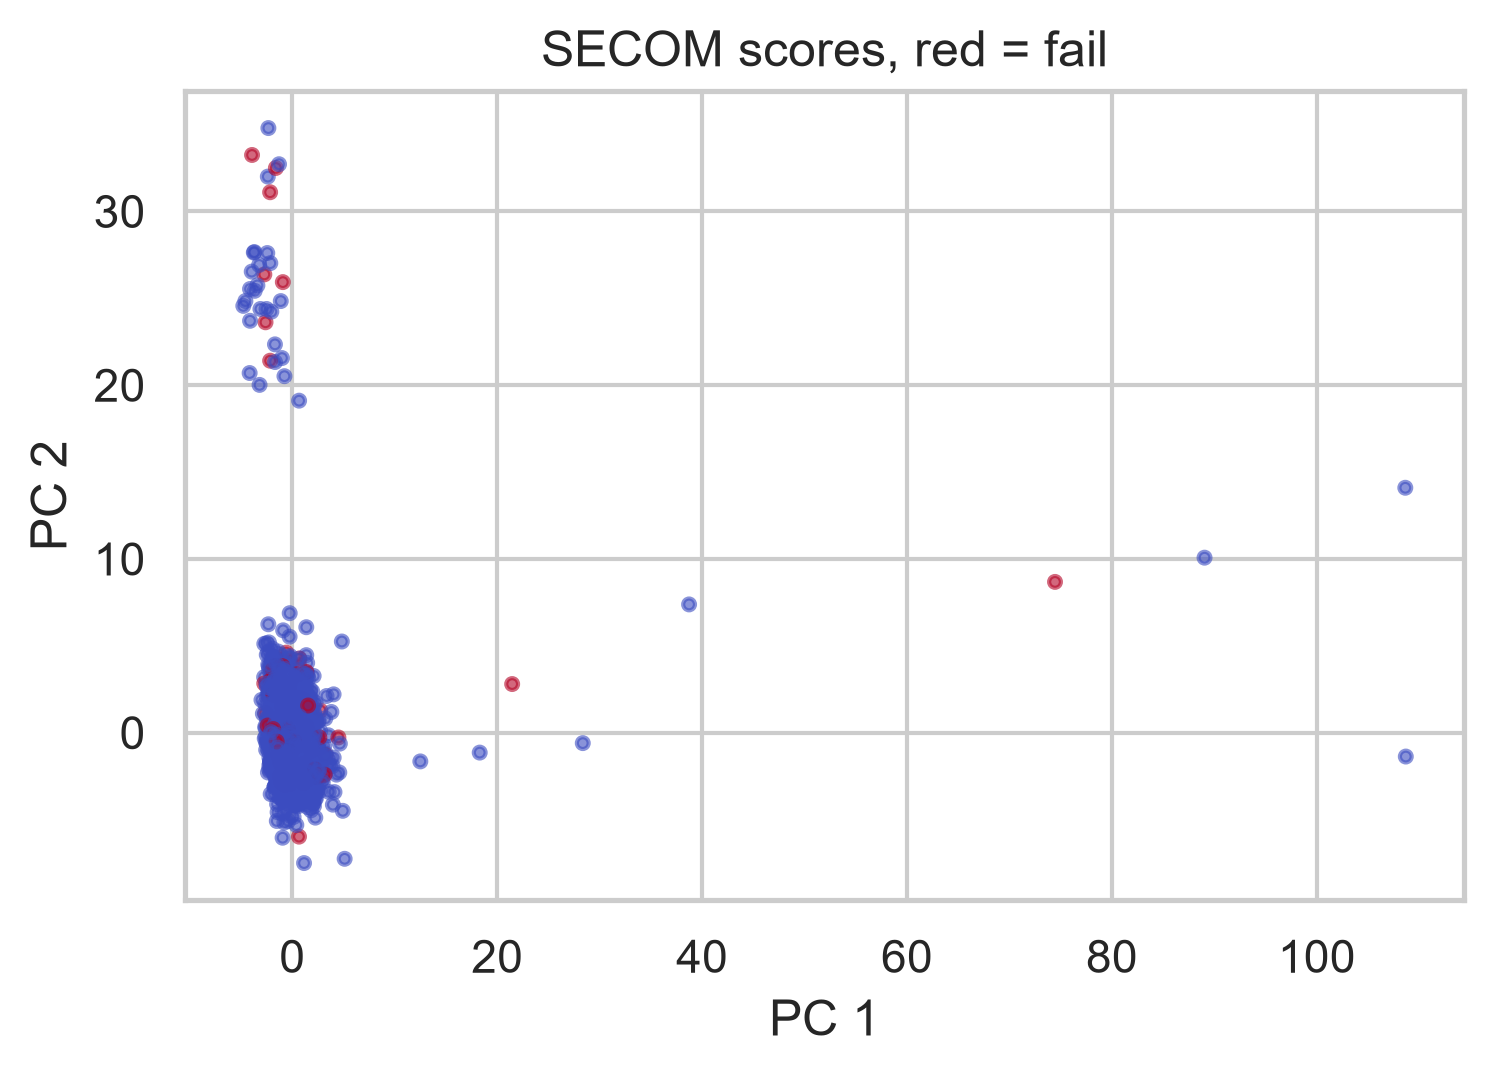

C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


k = 2: failure rate per cluster [0.2, 0.066]
k = 3: failure rate per cluster [0.049, 0.084, 0.25]


C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


k = 4: failure rate per cluster [0.08, 0.25, 0.047, 0.212]
k = 5: failure rate per cluster [0.06, 0.072, 0.05, 0.25, 0.219]


k = 6: failure rate per cluster [0.137, 0.041, 0.055, 0.219, 0.051, 0.25]


C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


In [9]:
#| code-fold: false
scores_s = pca_k.transform(prep.transform(X))[:, :2]
plt.scatter(scores_s[:, 0], scores_s[:, 1], c=(y == 1), cmap="coolwarm", s=8, alpha=0.6)
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.title("SECOM scores, red = fail")
plt.show()

Zall = prep.transform(X)
for k_ in range(2, 7):
    lab = KMeans(k_, n_init=10, random_state=0).fit_predict(Zall)
    rates = pd.Series(y.values == 1).groupby(lab).mean()
    print(f"k = {k_}: failure rate per cluster", rates.round(3).tolist())

The failed runs are scattered among the passed ones in the first two components, and the failure rate per cluster stays close to the overall rate of about 6–7 %. The dominant sources of variation in SECOM (e.g. tool or recipe changes) are not related to the pass/fail outcome. Clustering finds the largest structure in the data – which need not be the structure we are interested in.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

In [10]:
#| code-fold: false
with zipfile.ZipFile(hz) as z:
    ps = {s: read_sensor(z, f"{s}.txt") for s in ["PS1", "PS2", "PS3", "PS4", "PS5", "PS6"]}
feat_ps = pd.DataFrame({f"{s}_{stat}": getattr(np, stat)(v, axis=1)
                        for s, v in ps.items() for stat in ["mean", "std", "max"]})
Zp = StandardScaler().fit_transform(feat_ps)
lab_ps = KMeans(4, n_init=10, random_state=0).fit_predict(Zp)

from sklearn.metrics import adjusted_rand_score
{c: round(adjusted_rand_score(profile[c], lab_ps), 3) for c in ["cooler", "valve", "pump_leak", "accumulator"]}

C:\Tools\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


{'cooler': 0.585, 'valve': 0.034, 'pump_leak': 0.094, 'accumulator': 0.04}

The adjusted Rand index (0 = random agreement, 1 = identical grouping) shows which component condition the clusters reflect. Pressure features respond strongly to the valve condition (switching behaviour) and the accumulator pre-charge pressure, while the temperatures reflected the cooler. Different sensors "see" different faults – a central insight for designing condition monitoring systems.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4
Possible reasons: (1) the measurements are summary values per run and may not capture the physical cause of the failure; (2) the failures may have several different causes, so there is no single "failure direction"; (3) many features are noise, and in high dimensions the distance to normal data grows for *every* point, which dilutes anomaly scores; (4) only about 100 failures are available, and labels may be noisy; (5) part of the failures may originate in later process steps that are not measured at all. More sensors do not help if they do not measure the right thing.
:::